# Proyecto ML - Parte 2
Jose Manuel Fonseca, Julian Pinto y Daniel Vergara

## Contexto y objetivo
Vamos a clasificar reseñas como positivas, negativas o neutrales usando aprendizaje profundo. Esta vez hay textos en español, inglés, portugués, francés y mezclas de español e inglés. También aparecen ironía, negaciones y opiniones indirectas.

Compararemos un modelo sin aumento de datos con el mismo modelo entrenado con aumento. Revisaremos accuracy, F1 y errores por idioma. No usaremos eval para entrenar ni para generar etiquetas con una API.

El enunciado anuncia 20.466 reseñas de entrenamiento y 6.781 de evaluación. Los datos de la primera parte no sustituyen estos archivos.


## Imports
Empezamos con las herramientas de revisión de datos. Añadiremos la librería de redes cuando elijamos la arquitectura y el entorno de entrenamiento.


In [1]:
from pathlib import Path
import hashlib
import platform
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

display(pd.Series({
    'Python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
}, name='Version'))


Python    3.12.13
numpy       2.5.3
pandas      3.0.6
Name: Version, dtype: str

## Carga y comprobación de archivos
Los tres CSV de la nueva competencia deben estar junto al notebook. Comprobamos su tamaño antes de continuar para no mezclar las dos partes. Si Kaggle publica una corrección de los datos, revisaremos estos valores con la nueva versión.


In [2]:
CARPETA_DATOS = Path('.')
nombres = ['train.csv', 'eval.csv', 'sample_submission.csv']
faltantes = [nombre for nombre in nombres if not (CARPETA_DATOS / nombre).is_file()]
if faltantes:
    raise FileNotFoundError(f'Faltan los CSV de Parte 2: {faltantes}')

train = pd.read_csv(CARPETA_DATOS / 'train.csv')
eval_df = pd.read_csv(CARPETA_DATOS / 'eval.csv')
plantilla = pd.read_csv(CARPETA_DATOS / 'sample_submission.csv')

display(pd.DataFrame({
    'archivo': nombres,
    'filas': [len(train), len(eval_df), len(plantilla)],
    'esperadas': [20466, 6781, 6781],
}))
if (len(train), len(eval_df), len(plantilla)) != (20466, 6781, 6781):
    raise ValueError('Los tamaños no coinciden con el enunciado de Parte 2. Verificar la descarga antes de entrenar.')

assert set(train.columns) == {'id', 'text', 'label'}
assert set(eval_df.columns) == {'id', 'text'}
assert list(plantilla.columns) == ['id', 'answer']
assert train['label'].isin(['negativo', 'neutral', 'positivo']).all()
assert train['id'].notna().all() and train['id'].is_unique
assert eval_df['id'].notna().all() and eval_df['id'].is_unique
assert eval_df['id'].tolist() == plantilla['id'].tolist()

huellas_datos = {
    nombre: hashlib.sha256((CARPETA_DATOS / nombre).read_bytes()).hexdigest()
    for nombre in nombres
}
display(train.head())


,archivo,filas,esperadas
0,train.csv,20466,20466
1,eval.csv,6781,6781
2,sample_submission.csv,6781,6781


,id,text,label
0,0,Lo pedí un martes por internet y llegó al terc...,negativo
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo
2,2,Lo compré hace como dos meses en una tienda de...,neutral
3,3,Le routeur capte très bien dans toute la maiso...,negativo
4,4,"I got it a while back on sale online, it arriv...",neutral


## Revisión inicial
Revisaremos nulos, textos vacíos, identificadores y clases. No eliminaremos ni completaremos reseñas automáticamente antes de entender cada problema. Conservaremos tildes, puntuación, mayúsculas y negaciones como punto de partida: pueden aportar información en varios idiomas.


,train,eval
Textos nulos,0,0
Textos vacios o con espacios,0,0
Textos duplicados no nulos,0,0
Identificadores nulos,0,0
Identificadores repetidos,0,0


,Nulos por columna en train
id,0
text,0
label,0


,Cantidad,Porcentaje
label,,
positivo,7486,36.58
negativo,7381,36.06
neutral,5599,27.36


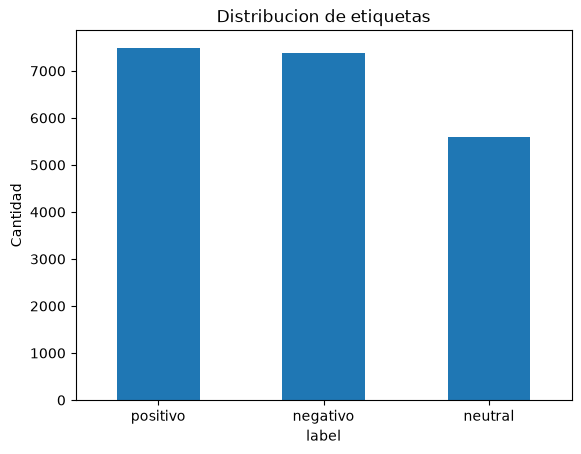

In [3]:
resumen = {}
for nombre, datos in [('train', train), ('eval', eval_df)]:
    textos = datos['text'].astype('string')
    resumen[nombre] = {
        'Textos nulos': textos.isna().sum(),
        'Textos vacios o con espacios': textos.str.strip().eq('').sum(),
        'Textos duplicados no nulos': textos.dropna().duplicated().sum(),
        'Identificadores nulos': datos['id'].isna().sum(),
        'Identificadores repetidos': datos['id'].duplicated().sum(),
    }
display(pd.DataFrame(resumen))
display(train.isna().sum().to_frame('Nulos por columna en train'))
conteos = train['label'].value_counts()
display(pd.DataFrame({
    'Cantidad': conteos,
    'Porcentaje': (conteos / len(train) * 100).round(2),
}))
conteos.plot.bar(title='Distribucion de etiquetas', rot=0, ylabel='Cantidad')
plt.show()


## Longitudes y coincidencias entre archivos

Comparamos longitudes por clase y buscamos textos iguales entre train y eval. Estas comprobaciones no usan etiquetas de eval ni permiten descartar por sí solas coincidencias aproximadas o traducciones.


In [4]:
textos_train = train['text'].astype('string')
textos_eval = eval_df['text'].astype('string')
display(pd.DataFrame({'Cantidad': [
    len(set(textos_train.dropna()) & set(textos_eval.dropna())),
    textos_train.str.lower().str.strip().dropna().duplicated().sum(),
]}, index=['Textos exactos compartidos train/eval',
          'Duplicados en train tras minusculas y espacios']))

longitudes = train.assign(palabras=textos_train.str.split().str.len())
display(longitudes.groupby('label')['palabras'].agg(
    ['count', 'mean', 'median', 'min', 'max']).round(2))


,Cantidad
Textos exactos compartidos train/eval,0
Duplicados en train tras minusculas y espacios,0


,count,mean,median,min,max
label,,,,,
negativo,7381,59.04,58.0,6,125
neutral,5599,53.16,53.0,3,100
positivo,7486,59.10,59.0,5,120


## Ejemplos de desarrollo

Leemos dos ejemplos por etiqueta para conocer las formas de expresar el sentimiento. Esta inspección no es una estimación de proporciones por idioma; el análisis multilingüe queda pendiente. La exploración inicial de train completo debe tenerse en cuenta al diseñar la validación.


In [5]:
for etiqueta in ['negativo', 'neutral', 'positivo']:
    print(f'\n{etiqueta.upper()}')
    ejemplos = train.loc[train['label'].eq(etiqueta), 'text'].sample(
        2, random_state=RANDOM_STATE)
    for numero, texto in enumerate(ejemplos, 1):
        print(f'{numero}. {texto}\n')



NEGATIVO
1. Compré esta carcasa hace un mes en una tienda de electrónica cerca de mi casa, la negra, porque la mía anterior se había roto con la mudanza. Doy mi punto de vista: la carcasa resultó veloz desde el primer día que la instalé en el escritorio. El envío no tardó nada y el peso me pareció normal. Aun así, la batería me resultó ser decepcionante para el precio que tiene.

2. Compré este reloj a inicios de mes en una tienda por departamentos del centro, pagué con tarjeta y me llegó en dos días. Hace un mes, lo uso a diario. La resistencia al agua me salió formidable en estas semanas, la probé en la alberca del club donde voy los sábados con mi cuñado. Con todo, la portabilidad me pareció terrible desde que lo estrené.


NEUTRAL
1. Lo compré a mediados de mes para usarlo aquí en casa, apenas llevo unos días con él. La entrega la hizo la mensajería de siempre y llegó en dos días, en la caja sellada. Lo dejé instalado en la sala y por ahora solo lo he usado por las tardes. Todavía

## Observaciones iniciales

Confirmamos los tamaños del enunciado y las columnas, etiquetas e identificadores esperados. No encontramos nulos, textos vacíos ni duplicados exactos dentro de cada archivo.

Distribución: negativo: 7,381 (36.06 %), neutral: 5,599 (27.36 %), positivo: 7,486 (36.58 %). Neutral tiene menos ejemplos, por lo que revisaremos también métricas por clase, no solo accuracy.

No se han eliminado filas, normalizado textos, generado aumentos ni entrenado modelos. Las siguientes secciones analizan idiomas y coincidencias cercanas para fijar la separación. La arquitectura sigue pendiente.


## Idiomas estimados

Usamos langid 1.1.6 localmente, limitado a es, en, pt y fr. No enviamos textos a una API. Es un modelo preentrenado auxiliar, no el clasificador de sentimiento. Su fuente y licencia BSD-2-Clause están en REFERENCIAS.md.

Si falta la dependencia, ejecutar `%pip install langid==1.1.6` en el kernel del notebook y reiniciarlo si es necesario.

La puntuación normalizada del detector no es una confianza calibrada con estas reseñas. Marcamos como inciertos los valores menores de 0,80 y los textos de menos de ocho palabras: en una revisión de train el detector llamó inglés a "Viene en beige" con puntuación alta. Para posibles mezclas es/en combinamos segmentos de al menos ocho palabras y señales manuales de inglés dentro de textos cuyo idioma dominante es español. Es una heurística: no garantiza encontrar todas las mezclas y puede producir falsos positivos. Otras mezclas entre idiomas se marcan cuando aparecen segmentos de varios idiomas con puntuación alta.

Estos umbrales son decisiones iniciales, no parámetros elegidos por accuracy de sentimiento. Los ejemplos se muestran para revisar sus limitaciones. Las categorías son estimaciones, no anotaciones oficiales; los futuros reportes por idioma deben indicarlo. Conservamos el texto original sin normalizar como entrada al futuro modelo.


In [6]:
import re
import unicodedata
from functools import lru_cache
from importlib.metadata import version
from threadpoolctl import threadpool_limits
from langid.langid import LanguageIdentifier, model

assert version('langid') == '1.1.6', 'Usar langid 1.1.6 para reproducir esta deteccion'
detector_idioma = LanguageIdentifier.from_modelstring(model, norm_probs=True)
detector_idioma.set_languages(['es', 'en', 'pt', 'fr'])
UMBRAL_IDIOMA = 0.80
UMBRAL_SEGMENTO = 0.90
PALABRAS_INGLES = {
    'the', 'this', 'that', 'with', 'was', 'were', 'would', 'have', 'has',
    'had', 'my', 'your', 'their', 'they', 'never', 'honestly', 'actually',
    'expected', 'disappointed', 'wife', 'husband', 'because', 'although',
    'however', 'really', 'works', 'worth', 'bought', 'returned',
    'crispy', 'wings', 'basket', 'dishwasher', 'coating', 'earbuds',
    'pairing', 'bass', 'full', 'phone', 'setup', 'sharp', 'crashing',
    'though', 'still', 'review', 'deal', 'battery', 'screen', 'broken',
}

@lru_cache(maxsize=100000)
def identificar_fragmento(texto):
    idioma, puntuacion = detector_idioma.classify(texto)
    return idioma, float(puntuacion)

def estimar_idioma(texto):
    dominante, puntuacion = identificar_fragmento(texto)
    partes = re.split(r'[.!?;]+', texto)
    segmentos = [p.strip() for p in partes if len(p.split()) >= 8]
    detectados = {
        idioma for segmento in segmentos
        for idioma, valor in [identificar_fragmento(segmento)]
        if valor >= UMBRAL_SEGMENTO
    }
    palabras = re.findall(r"[a-z]+", texto.casefold())
    pistas = [p for p in palabras if p in PALABRAS_INGLES]
    mezcla_segmentos = {'es', 'en'}.issubset(detectados)
    mezcla_palabras = dominante == 'es' and len(set(pistas)) >= 3 and len(pistas) >= 4
    mixta = mezcla_segmentos or mezcla_palabras
    if mixta:
        grupo = 'es_en_probable'
    elif len(detectados) > 1:
        grupo = 'otra_mezcla_probable'
    else:
        grupo = dominante if puntuacion >= UMBRAL_IDIOMA and len(texto.split()) >= 8 else 'incierto'
    return {
        'idioma_dominante': dominante,
        'puntuacion_idioma': puntuacion,
        'idioma_estimado': grupo,
        'mezcla_segmentos': mezcla_segmentos,
        'mezcla_palabras': mezcla_palabras,
    }

with threadpool_limits(limits=1):
    idiomas_train = pd.DataFrame([estimar_idioma(t) for t in train['text']])
    idiomas_eval = pd.DataFrame([estimar_idioma(t) for t in eval_df['text']])

tabla_idiomas = pd.concat({
    'train': idiomas_train['idioma_estimado'].value_counts(),
    'eval': idiomas_eval['idioma_estimado'].value_counts(),
}, axis=1).fillna(0).astype(int)
tabla_idiomas['train %'] = (tabla_idiomas['train'] / len(train) * 100).round(2)
tabla_idiomas['eval %'] = (tabla_idiomas['eval'] / len(eval_df) * 100).round(2)
display(tabla_idiomas)
display(pd.crosstab(idiomas_train['idioma_estimado'], train['label']))
print('Version langid:', version('langid'))


,train,eval,train %,eval %
idioma_estimado,,,,
es,13500,4048,65.96,59.70
en,2350,927,11.48,13.67
pt,2309,911,11.28,13.43
fr,2072,796,10.12,11.74
es_en_probable,112,59,0.55,0.87
otra_mezcla_probable,77,34,0.38,0.50
incierto,46,6,0.22,0.09


label,negativo,neutral,positivo
idioma_estimado,,,
en,775,749,826
es,4982,3556,4962
es_en_probable,50,1,61
fr,735,564,773
incierto,14,19,13
otra_mezcla_probable,22,23,32
pt,803,687,819


Version langid: 1.1.6


### Ejemplos y dudas del detector

Leemos ejemplos únicamente de train, priorizando los de menor puntuación en cada grupo. No corregimos el sentimiento ni afirmamos que la estimación de idioma sea una verdad. Los préstamos de palabras de productos no siempre son code-switching. No usaremos la distribución de eval para escoger hiperparámetros, aumentar ejemplos o ajustar el clasificador.


In [7]:
revision_idiomas = train[['id', 'text', 'label']].join(idiomas_train)
for idioma, filas in revision_idiomas.groupby('idioma_estimado'):
    print(f'\nIDIOMA ESTIMADO: {idioma} ({len(filas)} ejemplos)')
    for fila in filas.sort_values(['puntuacion_idioma', 'id']).head(2).itertuples():
        print(f'id={fila.id}; etiqueta={fila.label}; puntuacion={fila.puntuacion_idioma:.3f}')
        print(fila.text)



IDIOMA ESTIMADO: en (2350 ejemplos)
id=4; etiqueta=neutral; puntuacion=1.000
I got it a while back on sale online, it arrived in about four days. It's a charger that works off a USB-C port, none of that old connector stuff. I haven't really used it much yet, just tried it out a couple of times around the house. For now it's just sitting in my desk drawer.
id=9; etiqueta=positivo; puntuacion=1.000
The color accuracy on this monitor is genuinely impressive for photo editing, and I've noticed details in my work I couldn't see before. That said, the stand wobbles every time I bump the desk, which is annoying during long sessions. Some days the image quality wins me over, other days the instability wears me down. I keep going back and forth on whether I'd buy it again.

IDIOMA ESTIMADO: es (13500 ejemplos)
id=17106; etiqueta=neutral; puntuacion=0.999
Hace un mes, se lo compré a un familiar. Viene en color gris.
id=12288; etiqueta=neutral; puntuacion=1.000
Aporto mi granito de arena. Lo ped

## Grupos de reseñas muy parecidas

Antes de separar, agrupamos coincidencias tras unificar tildes, mayúsculas y puntuación, y candidatos casi idénticos por similitud de caracteres de al menos 0,985. La normalización se usa solo para agrupar, no para cambiar las entradas del modelo. Un grupo puede tener etiquetas distintas; no las cambiamos ni eliminamos filas.

Buscamos vecinos con TF-IDF de caracteres y unimos las conexiones. Esta representación se ajusta solo sobre train para diseñar grupos; no se reutilizará como característica del modelo de sentimiento. No se ajusta con eval. Es una precaución contra coincidencias cercanas, no un detector de traducciones o paráfrasis: estas pueden escapar. Los datos aumentados futuros heredarán la partición de su original.


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def clave_grupo(texto):
    texto = unicodedata.normalize('NFKD', texto.casefold())
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return ' '.join(re.findall(r'[^\W_]+', texto, flags=re.UNICODE))

claves = train['text'].map(clave_grupo)
origen, destino = [], []
primera = {}
for i, clave in enumerate(claves):
    if clave in primera:
        origen.append(i)
        destino.append(primera[clave])
    else:
        primera[clave] = i

SIMILITUD_MINIMA = 0.985
vector_grupos = TfidfVectorizer(
    analyzer='char_wb', ngram_range=(3, 5), min_df=2,
    max_features=100000, dtype=np.float32,
)
matriz_grupos = vector_grupos.fit_transform(claves)
buscador = NearestNeighbors(metric='cosine', algorithm='brute', n_jobs=1).fit(matriz_grupos)
with threadpool_limits(limits=1):
    for inicio in range(0, len(train), 128):
        distancias, vecinos = buscador.radius_neighbors(
            matriz_grupos[inicio:inicio + 128], radius=1 - SIMILITUD_MINIMA,
            return_distance=True,
        )
        for local, (dist, indices) in enumerate(zip(distancias, vecinos)):
            i = inicio + local
            for d, j in zip(dist, indices):
                if j > i:
                    origen.append(i)
                    destino.append(int(j))

grafo = coo_matrix((np.ones(len(origen)), (origen, destino)), shape=(len(train), len(train)))
_, grupos = connected_components(grafo, directed=False)
tamanos_grupos = pd.Series(grupos).value_counts()
display(pd.Series({
    'Grupos': len(tamanos_grupos),
    'Grupos con mas de una resena': (tamanos_grupos > 1).sum(),
    'Resenas dentro de grupos repetidos': tamanos_grupos[tamanos_grupos > 1].sum(),
    'Tamano del grupo mayor': tamanos_grupos.max(),
}))
revision_grupos = train[['id', 'text', 'label']].assign(grupo=grupos)
grupos_varios = tamanos_grupos.index[tamanos_grupos > 1]
with pd.option_context('display.max_colwidth', 180):
    display(revision_grupos.loc[revision_grupos['grupo'].isin(grupos_varios[:3])])
print('Grupos con etiquetas diferentes:',
      revision_grupos.groupby('grupo')['label'].nunique().gt(1).sum())


Grupos                                20463
Grupos con mas de una resena              3
Resenas dentro de grupos repetidos        6
Tamano del grupo mayor                    2
dtype: int64

,id,text,label,grupo
503,503,"Bought this office chair in March for my home desk, mostly for work calls and my son's homework hour. Assembly took me about twenty minutes, one missing bolt but support sent i...",positivo,503
1488,1488,"La compré en enero para el escritorio donde hago mis pendientes de la casa, porque la anterior ya sonaba rara. Mi esposo la arma en media hora (eso sí, pidan ayuda con la caja,...",negativo,1488
5158,5158,"La compré en enero para el escritorio donde hago mis pendientes de la casa, porque la anterior ya sonaba rara. Mi esposo la arma en media hora (eso sí, pidan ayuda con la caja,...",positivo,1488
9638,9638,"Bought this wifi router in March for the home office, mainly because my husband works from home and streams at night. Compared with the previous model, this one performs better...",positivo,9637
10711,10711,"Bought this office chair in March for my home desk, mostly for work calls and my son's homework hour. Assembly took me about twenty minutes, one missing bolt but support sent i...",negativo,503
13763,13763,"Bought this wifi router in March for the home office, mainly because my husband works from home and streams at night. Compared with the previous model, the old one performs bet...",negativo,9637


Grupos con etiquetas diferentes: 3


## Separación de entrenamiento y validación

Usamos aproximadamente 80 % para entrenamiento y 20 % para validación. Una separación estratificada por sentimiento e idioma estimado intenta mantener ambos representados; los grupos textuales nunca se dividen. Elegimos la primera de cinco particiones con semilla 42 antes de entrenar, no la que tenga mejor score. Si un estrato tiene menos de cinco grupos, se une al estrato mayor de su mismo sentimiento solo para calcular la separación y se muestra el aviso. No se cambia el idioma estimado guardado ni se garantiza que todo subgrupo pequeño aparezca en ambas partes.

La validación queda fija y sin aumento. Mostramos su composición, pero no leemos aquí sus reseñas ni usamos sus resultados para entrenar. No hay una segunda reserva ciega: reutilizar esta validación para muchas decisiones puede sobreajustarla; la exploración previa incluyó train completo. El marcador público no sustituye esta evaluación y el privado sigue siendo desconocido.


In [9]:
from sklearn.model_selection import StratifiedGroupKFold

estratos = train['label'] + '|' + idiomas_train['idioma_estimado']
grupos_por_estrato = pd.DataFrame({'estrato': estratos, 'grupo': grupos}).groupby('estrato')['grupo'].nunique()
escasos = grupos_por_estrato[grupos_por_estrato < 5].index
if len(escasos):
    print('Estratos escasos, se unen al estrato mayor de su sentimiento:', list(escasos))
    for etiqueta in train['label'].unique():
        candidatos = grupos_por_estrato.loc[grupos_por_estrato.index.str.startswith(etiqueta + '|')]
        principal = candidatos.idxmax()
        if candidatos.max() < 5:
            raise ValueError('No hay suficientes grupos para separar cinco partes de esta clase.')
        mascara = estratos.isin(escasos) & train['label'].eq(etiqueta)
        estratos = estratos.where(~mascara, principal)

separador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
indices_train, indices_valid = next(separador.split(train['text'], estratos, groups=grupos))
assert not set(indices_train) & set(indices_valid)
assert len(indices_train) + len(indices_valid) == len(train)
assert not set(grupos[indices_train]) & set(grupos[indices_valid])
assert not set(claves.iloc[indices_train]) & set(claves.iloc[indices_valid])

particiones = train[['id', 'label']].join(idiomas_train)
particiones['grupo'] = grupos
particiones['particion'] = 'entrenamiento'
particiones.loc[indices_valid, 'particion'] = 'validacion'
particiones['sha256_train'] = huellas_datos['train.csv']

X_train = train['text'].iloc[indices_train].copy()
y_train = train['label'].iloc[indices_train].copy()
X_valid = train['text'].iloc[indices_valid].copy()
y_valid = train['label'].iloc[indices_valid].copy()
idiomas_valid = idiomas_train.iloc[indices_valid].copy()
display(particiones['particion'].value_counts().to_frame('Cantidad'))
display(pd.crosstab([particiones['idioma_estimado'], particiones['label']], particiones['particion']))
display(pd.crosstab(particiones['particion'], particiones['label'], normalize='index').round(4))

if Path('particiones.csv').exists():
    anterior = pd.read_csv('particiones.csv')
    if not anterior[['id', 'grupo', 'particion', 'sha256_train']].equals(
        particiones[['id', 'grupo', 'particion', 'sha256_train']]):
        raise ValueError('La particion existente cambio: revisar datos, versiones y configuracion antes de reemplazarla.')
particiones.to_csv('particiones.csv', index=False)
print('Particiones guardadas; ningun grupo cruza entrenamiento y validacion.')
print('Versiones:', {'sklearn': version('scikit-learn'), 'scipy': version('scipy'), 'langid': version('langid')})


Estratos escasos, se unen al estrato mayor de su sentimiento: ['neutral|es_en_probable']


,Cantidad
particion,
entrenamiento,16373
validacion,4093


particion                      entrenamiento  validacion
idioma_estimado      label                              
en                   negativo            620         155
                     neutral             599         150
                     positivo            661         165
es                   negativo           3986         996
                     neutral            2845         711
                     positivo           3969         993
es_en_probable       negativo             40          10
                     neutral               1           0
                     positivo             49          12
fr                   negativo            588         147
                     neutral             451         113
                     positivo            619         154
incierto             negativo             11           3
                     neutral              15           4
                     positivo             10           3
otra_mezcla_probable negativo             18           4
                     neutral              18           5
                     positivo             26           6
pt                   negativo            642         161
                     neutral             550         137
                     positivo            655         164

label,negativo,neutral,positivo
particion,,,
entrenamiento,0.3607,0.2736,0.3658
validacion,0.3606,0.2736,0.3657


Particiones guardadas; ningun grupo cruza entrenamiento y validacion.
Versiones: {'sklearn': '1.9.1', 'scipy': '1.18.1', 'langid': '1.1.6'}


## Resultado y límites de esta preparación

Quedaron 16.373 reseñas de entrenamiento y 4.093 de validación. La separación se reprodujo en otra comprobación y ningún grupo detectado cruza ambas partes.

El idioma dominante estimado fue español en 65,96 % de train y 59,70 % de eval. Hay 112 reseñas de train marcadas como posible mezcla es/en, 77 de otra mezcla y 46 inciertas. Estos conteos no son la prevalencia real: el procedimiento omite mezclas y puede confundir idiomas. Los subgrupos pequeños darán métricas inestables y deben reportarse con su cantidad de ejemplos. La única neutral del grupo es/en probable quedó en entrenamiento; no se puede medir su recall en esa validación.

Se encontraron tres grupos de dos textos casi idénticos; cada par tiene etiquetas distintas. Eso no demuestra por sí solo un error de etiquetado: cambios pequeños pueden cambiar el sentimiento. Se mantuvieron juntos sin corregir respuestas. No se detectaron exhaustivamente traducciones ni paráfrasis.

El archivo particiones.csv conserva los id y grupos para repetir exactamente la comparación con y sin aumento. No se aumentará la validación ni se utilizará eval para entrenar. No hemos entrenado aún un clasificador de sentimiento.


## Próximo paso

Elegiremos la red profunda multilingüe y el entorno con GPU. La primera configuración se entrenará sin aumento usando X_train e y_train y se evaluará en X_valid e y_valid, incluyendo métricas por idioma estimado. Luego repetiremos con aumento solo en entrenamiento y mantendremos exactamente esta validación. No se ha entrenado todavía un clasificador de sentimiento.
